In [3]:
pip install ucimlrepo

In [5]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

# fetch dataset
ai4i_2020_predictive_maintenance_dataset = fetch_ucirepo(id=601)

# data (as pandas dataframes)
X = ai4i_2020_predictive_maintenance_dataset.data.features
y = ai4i_2020_predictive_maintenance_dataset.data.targets

# Create raw dataframe by joining features and targets
df_raw = pd.concat([X, y], axis=1)

# Standardize column names (removing units for easy processing based on actual UCI names)
df = df_raw.rename(
    columns={
        "Air temperature": "Air_Temp",
        "Process temperature": "Process_Temp",
        "Rotational speed": "Rotational_Speed",
        "Torque": "Torque",
        "Tool wear": "Tool_Wear",
        "Machine failure": "Machine_Failure",
    }
)

print(f"Dataset Shape: {df.shape[0]} records, {df.shape[1]} attributes")
display(df.head())


# 2. FUNCTION TO EXPORT DIRECTLY AS .ARFF FOR WEKA 
def export_to_arff(dataframe, filename="predictive_maintenance.arff"):
  with open(filename, "w") as f:
    f.write("@relation predictive_maintenance_ai4i\n\n")
    for col in dataframe.columns:
      if dataframe[col].dtype == "object" or col == "Machine_Failure":
        vals = "{" + ",".join([str(v) for v in dataframe[col].unique()]) + "}"
        f.write(f"@attribute {col} {vals}\n")
      else:
        f.write(f"@attribute {col} NUMERIC\n")
    f.write("\n@data\n")
    for row in dataframe.itertuples(index=False):
      f.write(",".join([str(val) for val in row]) + "\n")
  print(
      f"✅ Exported '{filename}'! (Download this file to open directly in WEKA)"
  )


export_to_arff(
    df[[
        "Type",
        "Air_Temp",
        "Process_Temp",
        "Rotational_Speed",
        "Torque",
        "Tool_Wear",
        "Machine_Failure",
    ]]
)

Dataset Shape: 10000 records, 12 attributes


,Type,Air_Temp,Process_Temp,Rotational_Speed,Torque,Tool_Wear,Machine_Failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


✅ Exported 'predictive_maintenance.arff'! (Download this file to open directly in WEKA)


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# 1. Check Missing Values
print("Missing values per column:\n", df.isnull().sum())

# 2. Drop unique row identifiers and individual failure types not needed for modeling
# We use errors="ignore" to prevent KeyErrors if UDI or Product ID are missing from the dataframe
features_df = df.drop(
    columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"],
    errors="ignore"
)

# 3. Categorical Encoding (Type: L, M, H -> 0, 1, 2)
le = LabelEncoder()
features_df["Type"] = le.fit_transform(features_df["Type"])

# 4. Feature and Target Split
X = features_df.drop(columns=["Machine_Failure"])
y = features_df["Machine_Failure"]

# 5. Normalization (Min-Max Scaling)
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 6. Train-Test Split (80% Train, 20% Test, Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
print(f"\n✅ Training set: {X_train.shape[0]} | Testing set: {X_test.shape[0]}")

Missing values per column:
 Type                0
Air_Temp            0
Process_Temp        0
Rotational_Speed    0
Torque              0
Tool_Wear           0
Machine_Failure     0
TWF                 0
HDF                 0
PWF                 0
OSF                 0
RNF                 0
dtype: int64

✅ Training set: 8000 | Testing set: 2000


In [8]:
print("--- [OLAP: DATA CUBE OPERATIONS] ---")

# A. Slice: Examine High-Wear operations (Tool Wear > 200 min)
slice_df = df[df["Tool_Wear"] > 200]
print(
    f"1. SLICE (Tool Wear > 200 mins): {len(slice_df)} records, Failure Rate:"
    f" {slice_df['Machine_Failure'].mean():.2%}"
)

# B. Dice: Focus on Product Type 'H' with High Torque (> 50 Nm)
dice_df = df[(df["Type"] == "H") & (df["Torque"] > 50)]
print(
    f"2. DICE (Product Type 'H' AND Torque > 50): {len(dice_df)} records,"
    f" Failure Rate: {dice_df['Machine_Failure'].mean():.2%}"
)

# C. Roll-up: Aggregate failures by Product Quality Type
rollup_df = (
    df.groupby("Type")
    .agg(
        Total_Units=("Machine_Failure", "count"),
        Failures=("Machine_Failure", "sum"),
        Avg_Torque=("Torque", "mean"),
    )
    .reset_index()
)
print("\n3. ROLL-UP (Aggregated by Product Type):")
display(rollup_df)

# D. Drill-down: Cross-tabulate Failure types across Product Types
drilldown_df = df.groupby("Type")[["TWF", "HDF", "PWF", "OSF"]].sum()
print("\n4. DRILL-DOWN (Specific Failure Modes across Product Types):")
display(drilldown_df)

--- [OLAP: DATA CUBE OPERATIONS] ---
1. SLICE (Tool Wear > 200 mins): 762 records, Failure Rate: 15.49%
2. DICE (Product Type 'H' AND Torque > 50): 144 records, Failure Rate: 8.33%

3. ROLL-UP (Aggregated by Product Type):


,Type,Total_Units,Failures,Avg_Torque
0,H,1003,21,39.838285
1,L,6000,235,39.996600
2,M,2997,83,40.017251



4. DRILL-DOWN (Specific Failure Modes across Product Types):


,TWF,HDF,PWF,OSF
Type,,,,
H,7,8,5,2
L,25,76,59,87
M,14,31,31,9


--- [INFORMATION GAIN MEASURES] ---


,Feature,Information_Gain
0,Torque,0.046021
1,Rotational_Speed,0.036359
2,Tool_Wear,0.013370
3,Air_Temp,0.006439
4,Type,0.003845
5,Process_Temp,0.001947


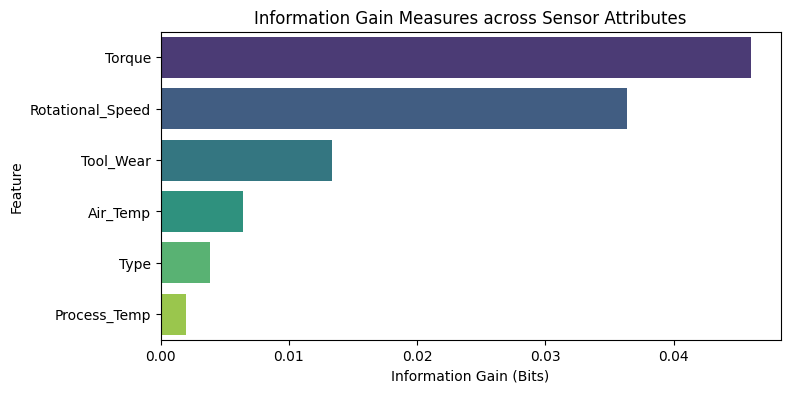

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# Calculate Information Gain (Mutual Information)
info_gains = mutual_info_classif(X_scaled, y, random_state=42)
ig_df = (
    pd.DataFrame({"Feature": X.columns, "Information_Gain": info_gains})
    .sort_values(by="Information_Gain", ascending=False)
    .reset_index(drop=True)
)

print("--- [INFORMATION GAIN MEASURES] ---")
display(ig_df)

# Plot Information Gain for Report Chapter 4
plt.figure(figsize=(8, 4))
sns.barplot(
    x="Information_Gain",
    y="Feature",
    data=ig_df,
    palette="viridis",
    hue="Feature",
    legend=False,
)
plt.title("Information Gain Measures across Sensor Attributes")
plt.xlabel("Information Gain (Bits)")
plt.savefig("information_gain.png", bbox_inches="tight")
plt.show()

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Define classification models
models = {
    "Decision Tree (J48 / C4.5)": DecisionTreeClassifier(
        criterion="entropy", max_depth=6, random_state=42
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42, class_weight="balanced"
    ),
    "Naive Bayes (Bayesian)": GaussianNB(),
    "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
}

results = []
conf_matrices = {}

for name, clf in models.items():
  clf.fit(X_train, y_train)
  y_pred = clf.predict(X_test)
  y_prob = (
      clf.predict_proba(X_test)[:, 1] if hasattr(clf, "predict_proba") else None
  )

  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred, zero_division=0)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  auc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0.0

  conf_matrices[name] = confusion_matrix(y_test, y_pred)
  results.append({
      "Algorithm": name,
      "Accuracy (%)": round(acc * 100, 2),
      "Precision": round(prec, 4),
      "Recall": round(rec, 4),
      "F1-Score": round(f1, 4),
      "ROC-AUC": round(auc, 4),
  })

comparison_df = pd.DataFrame(results)
print("--- [CHAPTER 6 & 7: MODEL COMPARISON TABLE] ---")
display(comparison_df)

--- [CHAPTER 6 & 7: MODEL COMPARISON TABLE] ---


,Algorithm,Accuracy (%),Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (J48 / C4.5),97.45,0.7576,0.3676,0.4950,0.9126
1,Logistic Regression,82.20,0.1418,0.8382,0.2426,0.9068
2,Naive Bayes (Bayesian),96.00,0.2857,0.1176,0.1667,0.9053
3,K-Nearest Neighbors (KNN),96.95,0.7059,0.1765,0.2824,0.8338


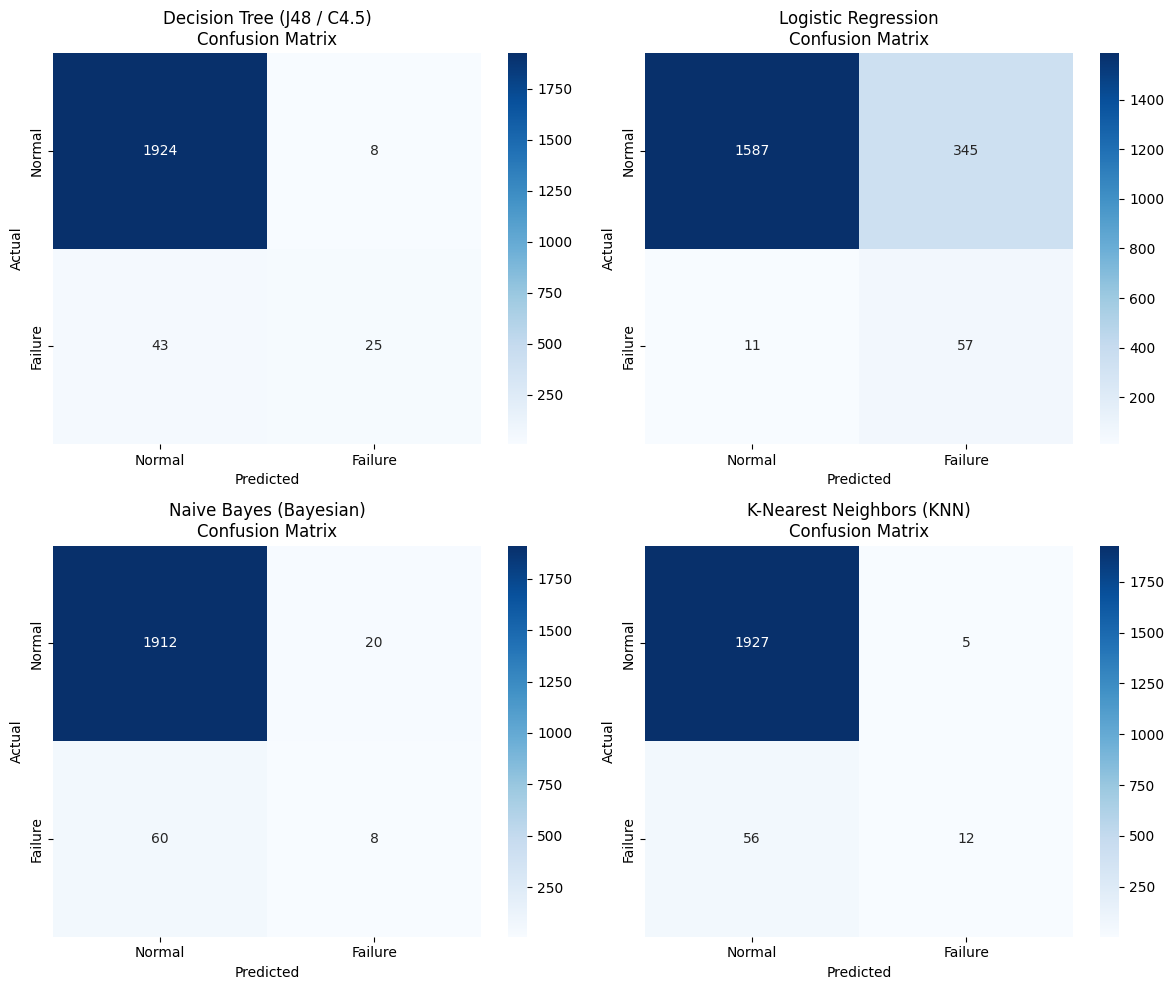

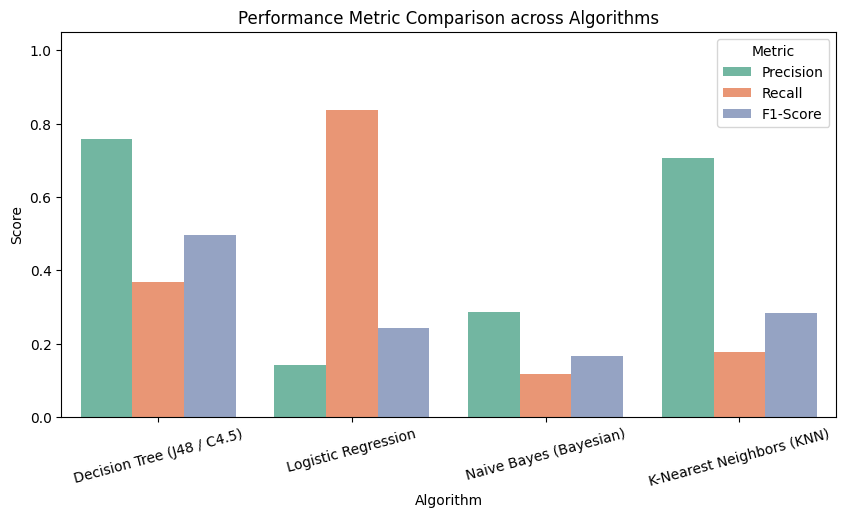

In [11]:
# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, cm) in enumerate(conf_matrices.items()):
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      ax=axes[idx],
      xticklabels=["Normal", "Failure"],
      yticklabels=["Normal", "Failure"],
  )
  axes[idx].set_title(f"{name}\nConfusion Matrix")
  axes[idx].set_xlabel("Predicted")
  axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices.png", bbox_inches="tight")
plt.show()

# Plot Evaluation Metrics Comparison Barplot
comparison_melted = pd.melt(
    comparison_df,
    id_vars=["Algorithm"],
    value_vars=["Precision", "Recall", "F1-Score"],
    var_name="Metric",
    value_name="Score",
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x="Algorithm",
    y="Score",
    hue="Metric",
    data=comparison_melted,
    palette="Set2",
)
plt.title("Performance Metric Comparison across Algorithms")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.savefig("algorithm_comparison.png", bbox_inches="tight")
plt.show()

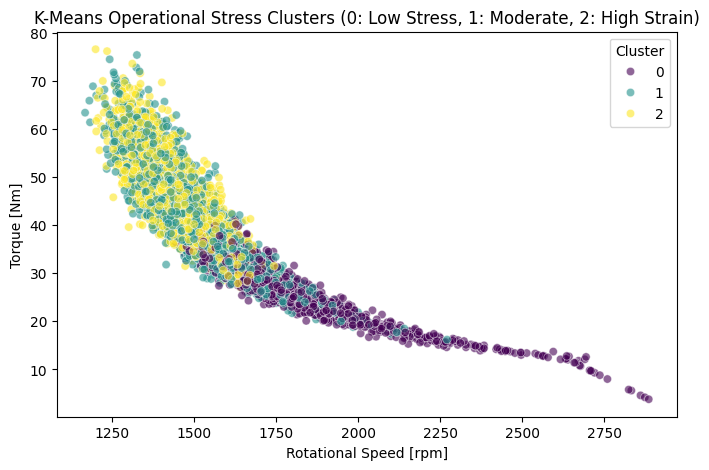

In [12]:
from sklearn.cluster import KMeans

# Operational stress clustering using Torque and Rotational Speed
cluster_data = X_scaled[["Torque", "Rotational_Speed", "Tool_Wear"]]

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(cluster_data)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=df["Rotational_Speed"],
    y=df["Torque"],
    hue=df["Cluster"],
    palette="viridis",
    alpha=0.6,
)
plt.title(
    "K-Means Operational Stress Clusters (0: Low Stress, 1: Moderate, 2: High"
    " Strain)"
)
plt.xlabel("Rotational Speed [rpm]")
plt.ylabel("Torque [Nm]")
plt.savefig("kmeans_clusters.png", bbox_inches="tight")
plt.show()

In [13]:
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

# Prepare boolean transaction matrix of machine failures & extreme conditions
basket = pd.DataFrame()
basket["High_Torque"] = df["Torque"] > df["Torque"].quantile(0.85)
basket["High_Temp"] = df["Process_Temp"] > df["Process_Temp"].quantile(0.85)
basket["High_Wear"] = df["Tool_Wear"] > df["Tool_Wear"].quantile(0.85)
basket["Tool_Wear_Failure"] = df["TWF"] == 1
basket["Heat_Dissipation_Failure"] = df["HDF"] == 1
basket["Power_Failure"] = df["PWF"] == 1
basket["Machine_Failure"] = df["Machine_Failure"] == 1

# A. Apriori
frequent_itemsets_apriori = apriori(
    basket, min_support=0.01, use_colnames=True
)
rules_apriori = association_rules(
    frequent_itemsets_apriori, metric="lift", min_threshold=1.5
)

# B. FP-Growth (Faster alternative)
frequent_itemsets_fp = fpgrowth(basket, min_support=0.01, use_colnames=True)
rules_fp = association_rules(
    frequent_itemsets_fp, metric="lift", min_threshold=1.5
)

print("--- [TOP 5 MINED ASSOCIATION RULES (FP-GROWTH)] ---")
display(
    rules_fp[["antecedents", "consequents", "support", "confidence", "lift"]]
    .sort_values(by="lift", ascending=False)
    .head(5)
)

--- [TOP 5 MINED ASSOCIATION RULES (FP-GROWTH)] ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
4,(Machine_Failure),(Heat_Dissipation_Failure),0.0115,0.339233,29.498525
5,(Heat_Dissipation_Failure),(Machine_Failure),0.0115,1.000000,29.498525
1,(Machine_Failure),(High_Torque),0.0210,0.619469,4.140836
0,(High_Torque),(Machine_Failure),0.0210,0.140374,4.140836
3,(High_Wear),(Machine_Failure),0.0151,0.101003,2.979450


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

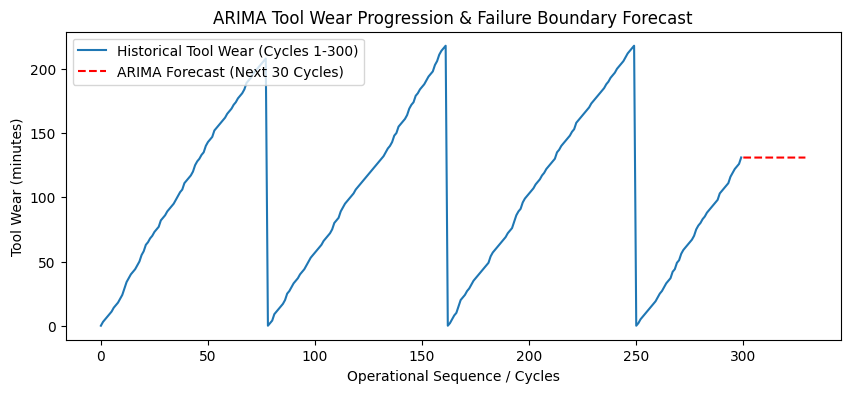

✅ ARIMA model successfully fit and forecasted!


In [14]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

# Aggregate Tool Wear progression over operational step windows
wear_series = df["Tool_Wear"].iloc[:300].values

# Fit an ARIMA model (p=2, d=1, q=1)
arima_model = ARIMA(wear_series, order=(2, 1, 1))
arima_fit = arima_model.fit()

# Forecast the next 30 operational cycles
forecast_steps = 30
forecast = arima_fit.forecast(steps=forecast_steps)

plt.figure(figsize=(10, 4))
plt.plot(
    range(len(wear_series)),
    wear_series,
    label="Historical Tool Wear (Cycles 1-300)",
)
plt.plot(
    range(len(wear_series), len(wear_series) + forecast_steps),
    forecast,
    label="ARIMA Forecast (Next 30 Cycles)",
    color="red",
    linestyle="--",
)
plt.title("ARIMA Tool Wear Progression & Failure Boundary Forecast")
plt.xlabel("Operational Sequence / Cycles")
plt.ylabel("Tool Wear (minutes)")
plt.legend()
plt.savefig("arima_forecast.png", bbox_inches="tight")
plt.show()
print("✅ ARIMA model successfully fit and forecasted!")